In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import folium

print("Library GIS berhasil disiapkan!")

Library GIS berhasil disiapkan!


In [2]:
data = [
    ["FAS-01", "Rumah Sakit A", "Kesehatan", -3.8000, 102.2650],
    ["FAS-02", "Puskesmas A", "Kesehatan", -3.8150, 102.2800],
    ["FAS-03", "Sekolah A", "Pendidikan", -3.7900, 102.2750],
    ["FAS-04", "Sekolah B", "Pendidikan", -3.8250, 102.2600],
    ["FAS-05", "Pasar A", "Perdagangan", -3.8050, 102.2900],
    ["FAS-06", "Pasar B", "Perdagangan", -3.8350, 102.2750],
    ["FAS-07", "Rumah Sakit B", "Kesehatan", -3.7850, 102.2500],
    ["FAS-08", "Sekolah C", "Pendidikan", -3.8100, 102.2500],
    ["FAS-09", "Pasar C", "Perdagangan", -3.8200, 102.3000],
    ["FAS-10", "Puskesmas B", "Kesehatan", -3.8400, 102.2900]
]

df = pd.DataFrame(
    data,
    columns=[
        "id", "nama", "kategori",
        "latitude", "longitude"
    ]
)

display(df)
print("Jumlah lokasi:", len(df))

,id,nama,kategori,latitude,longitude
0,FAS-01,Rumah Sakit A,Kesehatan,-3.800,102.265
1,FAS-02,Puskesmas A,Kesehatan,-3.815,102.280
2,FAS-03,Sekolah A,Pendidikan,-3.790,102.275
3,FAS-04,Sekolah B,Pendidikan,-3.825,102.260
4,FAS-05,Pasar A,Perdagangan,-3.805,102.290
5,FAS-06,Pasar B,Perdagangan,-3.835,102.275
6,FAS-07,Rumah Sakit B,Kesehatan,-3.785,102.250
7,FAS-08,Sekolah C,Pendidikan,-3.810,102.250
8,FAS-09,Pasar C,Perdagangan,-3.820,102.300
9,FAS-10,Puskesmas B,Kesehatan,-3.840,102.290


Jumlah lokasi: 10


In [3]:
print("Jumlah lokasi per kategori:")
display(df["kategori"].value_counts())

print("\nKoordinat lokasi:")
display(df[["latitude", "longitude"]].describe().round(5))

print("\nData kosong:")
display(df.isnull().sum())

Jumlah lokasi per kategori:


,count
kategori,
Kesehatan,4
Pendidikan,3
Perdagangan,3



Koordinat lokasi:


,latitude,longitude
count,10.00000,10.00000
mean,-3.81250,102.27350
std,0.01814,0.01717
min,-3.84000,102.25000
25%,-3.82375,102.26125
50%,-3.81250,102.27500
75%,-3.80125,102.28750
max,-3.78500,102.30000



Data kosong:


,0
id,0
nama,0
kategori,0
latitude,0
longitude,0


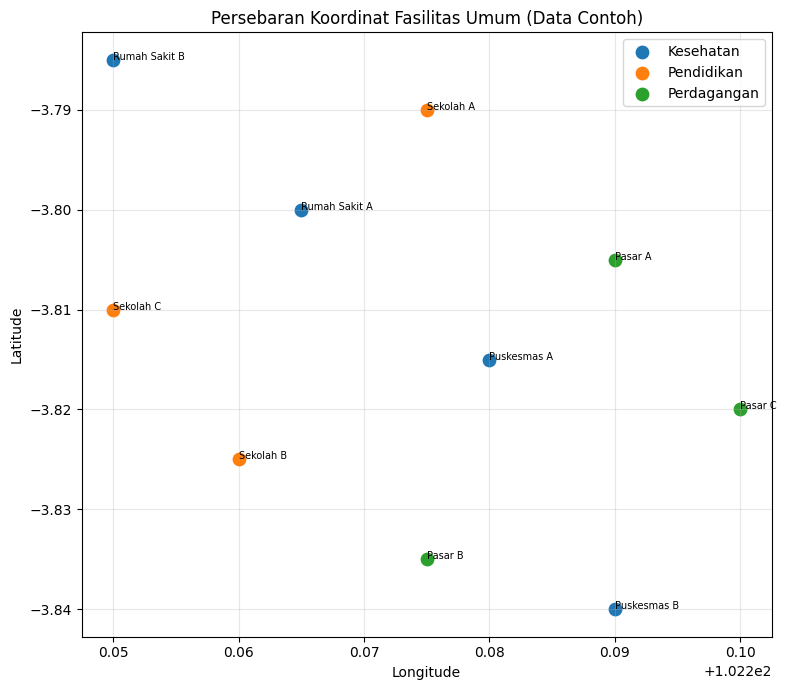

In [4]:
plt.figure(figsize=(8, 7))

for kategori in df["kategori"].unique():
    subset = df[df["kategori"] == kategori]

    plt.scatter(
        subset["longitude"],
        subset["latitude"],
        label=kategori,
        s=80
    )

    for _, row in subset.iterrows():
        plt.annotate(
            row["nama"],
            (row["longitude"], row["latitude"]),
            fontsize=7
        )

plt.title("Persebaran Koordinat Fasilitas Umum (Data Contoh)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
peta = folium.Map(
    location=[-3.815, 102.275],
    zoom_start=13
)

warna = {
    "Kesehatan": "red",
    "Pendidikan": "blue",
    "Perdagangan": "green"
}

for _, row in df.iterrows():
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=f"""
        <b>{row['nama']}</b><br>
        Kategori: {row['kategori']}<br>
        ID: {row['id']}
        """,
        tooltip=row["nama"],
        icon=folium.Icon(
            color=warna[row["kategori"]],
            icon="info-sign"
        )
    ).add_to(peta)

display(peta)

In [6]:
kategori_pilihan = "Kesehatan"

hasil_filter = df[df["kategori"] == kategori_pilihan]

print(f"Lokasi kategori {kategori_pilihan}:")
display(hasil_filter)

print("Jumlah lokasi:", len(hasil_filter))

Lokasi kategori Kesehatan:


,id,nama,kategori,latitude,longitude
0,FAS-01,Rumah Sakit A,Kesehatan,-3.800,102.265
1,FAS-02,Puskesmas A,Kesehatan,-3.815,102.280
6,FAS-07,Rumah Sakit B,Kesehatan,-3.785,102.250
9,FAS-10,Puskesmas B,Kesehatan,-3.840,102.290


Jumlah lokasi: 4


In [7]:
import numpy as np

def hitung_jarak_km(lat1, lon1, lat2, lon2):
    radius_bumi = 6371

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return radius_bumi * c

lokasi_acuan = df.iloc[0]

df["jarak_dari_lokasi_acuan_km"] = df.apply(
    lambda row: hitung_jarak_km(
        lokasi_acuan["latitude"],
        lokasi_acuan["longitude"],
        row["latitude"],
        row["longitude"]
    ),
    axis=1
)

display(
    df[["nama", "kategori", "jarak_dari_lokasi_acuan_km"]]
    .sort_values("jarak_dari_lokasi_acuan_km")
    .round(3)
)

,nama,kategori,jarak_dari_lokasi_acuan_km
0,Rumah Sakit A,Kesehatan,0.000
2,Sekolah A,Pendidikan,1.571
7,Sekolah C,Pendidikan,2.002
1,Puskesmas A,Kesehatan,2.356
6,Rumah Sakit B,Kesehatan,2.356
4,Pasar A,Perdagangan,2.829
3,Sekolah B,Pendidikan,2.835
5,Pasar B,Perdagangan,4.047
8,Pasar C,Perdagangan,4.475
9,Puskesmas B,Kesehatan,5.242


In [8]:
ringkasan = df.groupby("kategori").agg(
    jumlah_lokasi=("id", "count"),
    rata_rata_jarak_km=(
        "jarak_dari_lokasi_acuan_km", "mean"
    )
).round(3)

display(ringkasan)

print("Lokasi yang paling dekat dengan titik acuan:")
display(
    df.sort_values("jarak_dari_lokasi_acuan_km").head(3)[
        ["nama", "kategori", "jarak_dari_lokasi_acuan_km"]
    ].round(3)
)

,jumlah_lokasi,rata_rata_jarak_km
kategori,,
Kesehatan,4,2.489
Pendidikan,3,2.136
Perdagangan,3,3.784


Lokasi yang paling dekat dengan titik acuan:


,nama,kategori,jarak_dari_lokasi_acuan_km
0,Rumah Sakit A,Kesehatan,0.000
2,Sekolah A,Pendidikan,1.571
7,Sekolah C,Pendidikan,2.002
